# Ensemble Kalman Filtering with filterax

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/data_assimilation_etkf.ipynb)

*Part of the data-assimilation series; moved from somax's tutorial series.*

A sesmax model is a forward operator: on its own it only propagates a state. Data assimilation corrects that state against noisy, sparse observations of reality. This page wires a [Lorenz '96](lorenz96_simulation.ipynb) model into [filterax](https://github.com/jejjohnson/filterax) and runs an Ensemble Transform Kalman Filter (ETKF) twin experiment.

**What you'll learn:**

1. The `sesmax_core.da` adapters that bridge a model to a filterax filter
2. How to set up a twin experiment, a truth run with synthetic observations
3. How the analysis tracks the truth better than the forecast and the observations

:::{note}
This page needs the optional `[da]` extra, which provides filterax: `pip install sesmax-core[da]`.
:::

## Setup

On Colab, install `sesmax-core` with its `[da]` extra; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core[da] @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## The filter

A twin experiment observes the truth through an observation operator, with noise:

$$
\mathbf{y}_t = \mathbf{H} \mathbf{x}_t + \boldsymbol{\varepsilon}_t
$$

The ETKF alternates a forecast, which propagates each ensemble member through the model, with an analysis, which moves the ensemble toward the observations:

$$
\mathbf{x}_t^{(e)} = f(\mathbf{x}_{t-1}^{(e)}; F)
$$

$$
\boldsymbol{\mu}_{x,t \mid t} = \boldsymbol{\mu}_{x,t \mid t-1} + \mathbf{G}_t (\mathbf{y}_t - \mathbf{H} \boldsymbol{\mu}_{x,t \mid t-1})
$$

where the gain $\mathbf{G}_t$ comes from the ensemble's own covariance. The transform form updates the ensemble's mean and spread deterministically, without perturbing the observations.

### Symbols

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $\mathbf{x}_t$ | state at window $t$, the Lorenz '96 variables | $\mathbb{R}^{D_x}$ |
| $\mathbf{y}_t$ | observations at window $t$ | $\mathbb{R}^{D_y}$ |
| $\mathbf{H}$ | observation operator, here selecting observed entries | $D_y \times D_x$ |
| $\boldsymbol{\varepsilon}_t \sim \mathcal{N}(\mathbf{0}, \boldsymbol{\Sigma}_\varepsilon)$ | observation noise | $\mathbb{R}^{D_y}$ |
| $\boldsymbol{\Sigma}_\varepsilon$ | observation-error covariance | $D_y \times D_y$ |
| $\mathbf{x}_t^{(e)}$, $N_{\mathcal{E}}$ | ensemble member $e$, and the ensemble size | $\mathbb{R}^{D_x}$, count |
| $\boldsymbol{\mu}_{x,t \mid t-1}$, $\boldsymbol{\mu}_{x,t \mid t}$ | forecast and analysis means | $\mathbb{R}^{D_x}$ |
| $\mathbf{G}_t$ | gain | $D_x \times D_y$ |
| $f(\mathbf{x}; F)$, $F$ | the model over one window, and its forcing | $\mathbb{R}^{D_x}$, $\mathbb{R}$ |
| $N_T$ | number of observation windows | count |

### The `sesmax_core.da` bridge

filterax filters work on flat state vectors, and sesmax states are pytrees. Three small adapters span the gap, and a fourth observes the state:

| Object | Role |
| --- | --- |
| `FilteraxDynamics` | wraps `model.step` as a `filterax.AbstractDynamics` |
| `SubsampleObs` | sparse observation operator, $\mathbf{H} \mathbf{x}$ = `x[indices]` |
| `state_to_vector` | flattens a state pytree to a vector, and returns the inverse |
| `make_ensemble` | builds a perturbed flat ensemble around a state |

Because the dynamics adapter relies only on `model.step(state, dt, *, t0=...)`, any sesmax model drops in unchanged.

In [2]:
import einx
import jax
import jax.numpy as jnp
import lineax as lx
import matplotlib.pyplot as plt
from filterax import ETKF

import sesmax_core.testing as sxt
from sesmax_core.da import (
    FilteraxDynamics,
    SubsampleObs,
    make_ensemble,
    state_to_vector,
)

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. The truth run

We use a 40-variable Lorenz '96 system at $F = 8$, which is fully chaotic. The truth is spun up onto the attractor, then integrated forward in fixed windows of 0.05 time units. This trajectory is what the filter tries to recover; in a real problem it is unknown.

In [4]:
# Shapes: D_x = 40 variables; N_T = 40 windows; N_E = 40 members

num_variables = 40
window = 0.05
num_windows = 40
num_members = 40
obs_variance = 0.5

# today (sesmax_core)
model = sxt.Lorenz96.create(F=8.0)
# today (jax, sesmax_core)
step = jax.jit(lambda state: model.step(state, window))

# x₀ = F, with a small perturbation on the first variable
near_equilibrium = 8.0 * jnp.ones(num_variables)  # → (D_x,)
# today (sesmax_core)
spin_up = sxt.L96State(x=near_equilibrium.at[0].add(0.01))
for _ in range(300):
    spin_up = step(spin_up)
initial_truth = spin_up
print(f"Truth spun up: {initial_truth.x.shape}")

Truth spun up: (40,)


## 2. Synthetic observations

We observe every other variable, a 50% sparse network, with additive Gaussian noise. The observation operator is `SubsampleObs`, and its error covariance is a diagonal `lineax` operator.

In [5]:
# Shapes: D_x = 40 variables; D_y = 20 observed; N_T = 40 windows

key = jax.random.key(0)
# today (lineax)
# Σ_ε = σ² I
obs_covariance = lx.DiagonalLinearOperator(obs_variance * jnp.ones(20))
observed = jnp.arange(0, num_variables, 2)  # → (D_y,)
# today (sesmax_core)
obs_operator = SubsampleObs(indices=observed)

truth_vectors = []
observations = []
state = initial_truth
for index in range(1, num_windows + 1):
    state = step(state)
    # today (sesmax_core)
    truth_vector, _ = state_to_vector(state)  # → (D_x,)
    truth_vectors.append(truth_vector)
    key, noise_key = jax.random.split(key)
    # ε_t ~ 𝒩(0, Σ_ε)
    noise = jnp.sqrt(obs_variance) * jax.random.normal(noise_key, observed.shape)
    # y_t = H x_t + ε_t
    observations.append((truth_vector[observed] + noise, index * window))
truth = jnp.stack(truth_vectors)  # → (N_T, D_x)
print(f"{len(observations)} observation windows, {observed.size} observations each")

40 observation windows, 20 observations each


## 3. Run the ETKF

The ensemble is seeded by perturbing the initial truth, a stand-in for background uncertainty. `ETKF.assimilate` then loops forecast and analysis over every window: the forecast is the sesmax model vectorised over the ensemble through `FilteraxDynamics`, and the analysis is filterax's update.

In [6]:
# Shapes: N_T = 40 windows; N_E = 40 members; D_x = 40 variables

key, ensemble_key = jax.random.split(key)
# today (sesmax_core)
# x₀⁽ᵉ⁾ = x₀ + ε⁽ᵉ⁾
initial_ensemble = make_ensemble(  # → (N_E, D_x)
    initial_truth, ensemble_key, size=num_members, std=1.0
)
# today (filterax, sesmax_core)
etkf = ETKF(
    dynamics=FilteraxDynamics(model=model, template=initial_truth),
    obs_op=obs_operator,
)
# today (filterax)
result = etkf.assimilate(initial_ensemble, observations, obs_covariance, t0=0.0)

# μ_x,t|t
analysis_mean = einx.mean(  # → (N_T, D_x)
    "time [member] k -> time k", result.analysis_history
)
# μ_x,t|t−1
forecast_mean = einx.mean(  # → (N_T, D_x)
    "time [member] k -> time k", result.forecast_history
)
# ‖μ − x‖_RMS at each window
analysis_rmse = jnp.sqrt(  # → (N_T,)
    einx.mean("time [k] -> time", (analysis_mean - truth) ** 2)
)
forecast_rmse = jnp.sqrt(  # → (N_T,)
    einx.mean("time [k] -> time", (forecast_mean - truth) ** 2)
)

print(f"Mean analysis RMSE: {float(jnp.mean(analysis_rmse)):.3f}")
print(f"Mean forecast RMSE: {float(jnp.mean(forecast_rmse)):.3f}")
print(f"Observation-noise floor: {float(jnp.sqrt(obs_variance)):.3f}")

Mean analysis RMSE: 0.277
Mean forecast RMSE: 0.294
Observation-noise floor: 0.707


## 4. Does it work?

There are two checks. First, the per-window RMSE of the analysis should sit below the forecast and below the observation noise: the filter extracts more signal than any single observation carries, and half the variables are not observed at all. Second, the analysis error should stay small compared with the truth's own variability.

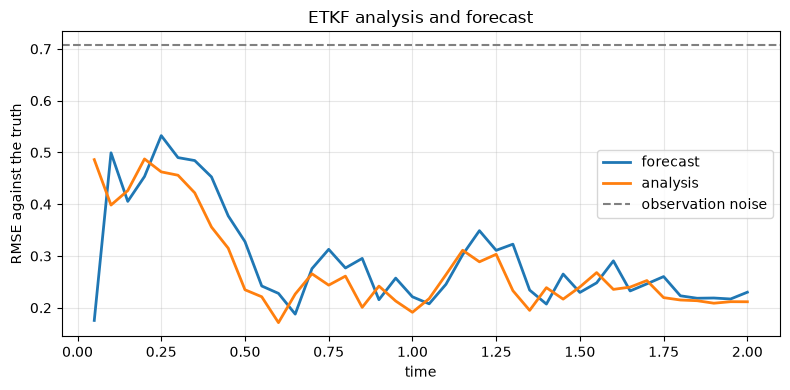

In [7]:
window_times = jnp.arange(1, num_windows + 1) * window  # → (N_T,)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(window_times, forecast_rmse, label="forecast", lw=2)
ax.plot(window_times, analysis_rmse, label="analysis", lw=2)
noise_floor = float(jnp.sqrt(obs_variance))
ax.axhline(noise_floor, ls="--", color="grey", label="observation noise")
ax.set_xlabel("time")
ax.set_ylabel("RMSE against the truth")
ax.set_title("ETKF analysis and forecast")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

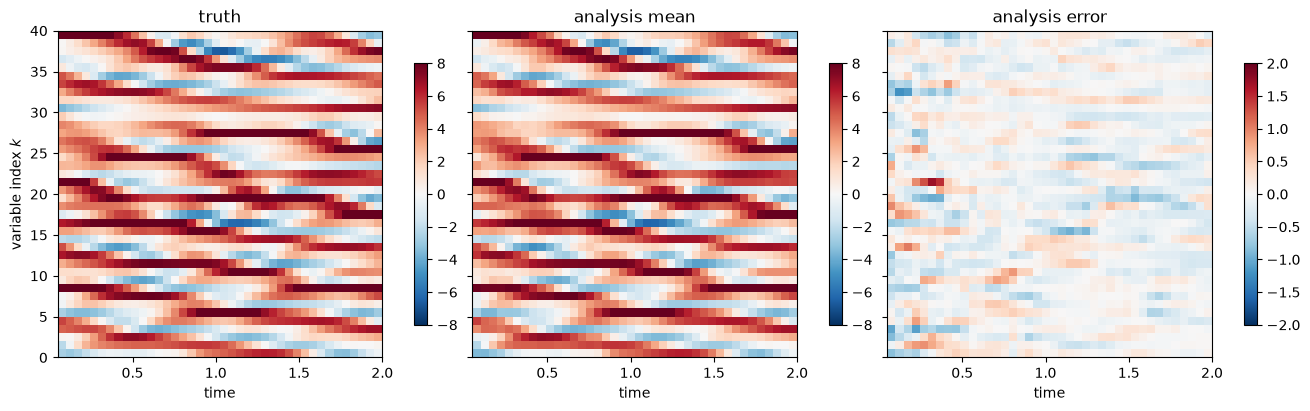

In [8]:
truth_panel = einx.id("time k -> k time", truth)  # → (D_x, N_T)
analysis_panel = einx.id("time k -> k time", analysis_mean)  # → (D_x, N_T)
error_panel = analysis_panel - truth_panel  # → (D_x, N_T)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True, layout="constrained")
extent = [float(window_times[0]), float(window_times[-1]), 0, num_variables]
for ax, panel, title, limit in [
    (axes[0], truth_panel, "truth", 8.0),
    (axes[1], analysis_panel, "analysis mean", 8.0),
    (axes[2], error_panel, "analysis error", 2.0),
]:
    image = ax.imshow(
        panel,
        aspect="auto",
        cmap="RdBu_r",
        vmin=-limit,
        vmax=limit,
        origin="lower",
        extent=extent,
    )
    ax.set_title(title)
    ax.set_xlabel("time")
    plt.colorbar(image, ax=ax, shrink=0.8)
axes[0].set_ylabel("variable index $k$")
plt.show()

## Summary

| Concept | sesmax API |
| --- | --- |
| Dynamics for a filter | `FilteraxDynamics(model=model, template=state)` |
| Sparse observations | `SubsampleObs(indices=...)` |
| Flatten a state | `state_to_vector(state)` |
| Seed an ensemble | `make_ensemble(state, key, size=..., std=...)` |

Swapping the model and the `template` state is all another model needs; the bridge is unchanged.